In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.mass_detect.note.config import CENTRE_INDEX, PATCHES_DIR, QC_FIGURE_FILE
from src.mass_detect.note.patches import cut_lidc_patches, cut_lndb_patches, summarise_manifest
from src.mass_detect.note.qc import check_patch_coordinates, make_patch_qc_figure

# Patches

The functions of this notebook live in `src/mass_detect/note/patches.py` (cutting) and `src/mass_detect/note/qc.py` (checks). Here we explain the choices, run them and look at the results.

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Patches
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Cutting 3D Patches (LNDb)
  </h3>
  <p>
  A patch is a cube of 64 mm around a center given in world coordinates (mm). It is resampled to 1 mm voxels, so the array has 64 x 64 x 64 voxels and the centre falls exactly on voxel (32, 32, 32). The values are raw Hounsfield units (int16). The array axes are (z, y, x) and they are aligned with the world axes, whatever the tilt of the CT, so every patch is oriented in the same way. Every feature is then measured in three dimensions inside this cube: the segmentation, size, shape, density, the ring around the nodule the sphere features and the radiomic features.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Why 3D Patches?
  </h3>
  <p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">A nodule and a vessel can look the same in one slice. A vessel cut across looks like a small round blob on an axial slice, exactly like a nodule. Only along the third axis does it reveals itself as a tube. Our segmentation relies on this: it removes the parts of the region that extend away from the nodule, which are mostly vessels and pleura. The detection literature shows the same effect. Setio et al. (2016) found that combining several views of a candidate works better than a single view, and Dou et al. (2017) showed that 3D context helps to tell nodules from false positives. Although thee studies use neural networks, the point still holds for any method since the third dimension carries information that a slice does not.</li>
    <li style="margin-bottom: 8px;">Size is the strongest predictor, and it is best measured as a volume. The Fleischner Society guidelines give their size thresholds both as diameters and as volumes (MacMahon et al., 2017). Volume, sphericity, elongation and flatness only exist in 3D, and a diameter measured on one slice depends on which slice is chosen.</li>
    <li style="margin-bottom: 8px;">Radiomic features are defined in 3D. The Image Biomarker Standardisation Initiative defines its shape and texture features on volumes and recommends isotropic voxels before computing them (Zwanenburg et al., 2020). Texture features change when the voxel size changes (Shafiq-ul-Hassan et al., 2017). Resampling every patch to 1 mm in all directions makes the features comparable between scans with different pixel sizes and slice spacings.</li>
    <li style="margin-bottom: 8px;">Almost all LNDb scans have 1 mm slices, so a 1 mm cube adds very little interpolation. The test file gives each candidate as a point in world coordinates (x, y, z), so a cube around that point is the natural unit. The cube is also what the LNDb authors distribute (the script getNoduleCubes.py cuts cubes of 51 mm). Recent work does the same: the foundation model of Pai et al. (2024) takes 50 mm cubes at 1 mm around the lesion centre.</li>
  </ul>
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   And why 64mm?
  </h3>

  <p>
  The largest rated LNDb nodule measures about 31 mm. A 64 mm cube holds it with room for the surrounding tissue (vessels, pleura, chest wall), which the ring features and the vessel removal need. Our choice for the specific number of 64 mm is a practical choice, close to the 50 to 51 mm used by the references.
  </p>
  <p>
  The following code cuts 3D patches around nodule centres, with the same procedure for training and test.
  </p>

</div>


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Patches for LIDC-IDRI
  </h3>
  <p>
  We'll cut the same patches for LIDC-IDRI nodules, to also be used as training data. But, since the LIDC-IDRI scans are folders of DICOM slices, we need to create another script to read the scan. Everything after reading the scan is shared with LNDb (the function extract_patch in patches.py), so a LIDC patch and a LNDb patch are cut in exactly the same way: 1 mm voxels, world axes, raw Hounsfield units.
  </p>
  <p>
SimpleITK reads the DICOM series, sorts the slices along the scan axis and applies RescaleSlope and RescaleIntercept, so the voxels are already in Hounsfield units. The csv nodule_table.csv keeps the centre of every LIDC nodule as voxel indices (row, column, slice) taken from pylidc. SimpleITK turns these indices into world coordinates using the origin, spacing and direction of the scan, which also works for the few scans whose slices are not axis aligned. 
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Checks and Helper Scripts
  </h3>
  <p>
    For readings that have a segmentation mask, the recorded centre should sit on the centre of the mask. We cut a patch of the mask around the recorded centre and measure how far the centroid of the mask is from voxel (32, 32, 32). Because voxels are 1 mm, the distance is already in millimetres. Large distances would mean swapped axes or the wrong coordinate system.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The following code draws a visual check of random patches: the three central views with the centre marked. The lung window (level -600 HU, width 1500 HU) is used only to display the patch. The patches themselves keep their raw HU values.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    3D Patches Around Every Finding
  </h1>

  <p>
    The model does not see a whole CT scan, only a small cube around each finding. This section explains how the cube is cut, shows that it is cut in the right place, and checks the result on all 1219 training findings and all 2900 test rows of LNDb. We'll use the code from the "3D Patches" section in the beginning of this document.
  </p>

</div>

In [ ]:
pd.set_option("display.width", 140)

# Cut the patches if they are not on disk yet (about 15 minutes for LNDb, 20 for LIDC). Functions: src/mass_detect/note/patches.py
for split in ("train", "test"):
    if not (PATCHES_DIR / f"manifest_{split}.csv").exists():
        summarise_manifest(cut_lndb_patches(split)[0], split)
if not (PATCHES_DIR / "manifest_lidc.csv").exists():
    cut_lidc_patches()
print("patches on disk:", {s: len(pd.read_csv(PATCHES_DIR / f'manifest_{s}.csv')) for s in ('train', 'test', 'lidc')})

patches on disk: {'train': 1219, 'test': 2900, 'lidc': 2663}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Unit Tests
  </h3>
  <p>
    Testing the patches - each test builds a CT with a smooth bright blob at a known physical point, cuts a patch around some centre and checks that the blob lands on the voxel where it must.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Testing our patches with a known answer
  </h3>
  <p>
    We build artificial scans with a bright blob at a known physical position, with different voxel sizes and tilts, and check that the blob lands on the middle voxel. A test only means something if it can fail, so we also broke the code on purpose in three ways (swapped axes, ignored tilt, a centre shifted by 3 mm) and each break was caught.
  </p>
  </ol>

In [34]:
from tests.test_patches import (test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing, test_axis_order_is_z_y_x,
    test_tilted_direction_is_handled, test_naive_conversion_would_fail_on_a_tilted_ct,
    test_points_outside_the_ct_are_filled_with_air_and_counted, test_nearest_neighbour_keeps_integer_labels)

for test in [test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing, test_axis_order_is_z_y_x, test_tilted_direction_is_handled, test_naive_conversion_would_fail_on_a_tilted_ct, test_points_outside_the_ct_are_filled_with_air_and_counted, test_nearest_neighbour_keeps_integer_labels]:
    test()
    print("passed:", test.__name__)

passed: test_blob_at_the_centre_lands_on_voxel_32_with_anisotropic_spacing
passed: test_axis_order_is_z_y_x
passed: test_tilted_direction_is_handled
passed: test_naive_conversion_would_fail_on_a_tilted_ct
passed: test_points_outside_the_ct_are_filled_with_air_and_counted
passed: test_nearest_neighbour_keeps_integer_labels


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Does it work on real scans?
  </h3>
  <p>
    For readings that come with a segmentation mask, the centre we cut around should fall on the centre of the mask. We cut a patch of the mask and measure how far its centre of mass is from the middle voxel. Since voxels are 1 mm, the distance is in millimetres. We used 12 scans: 6 tilted and 6 not tilted. If axes were swapped or the tilt ignored, the distance would be tens of millimetres.
  </p>
</div>

In [35]:
check_patch_coordinates()

45 readings with a mask, from 12 CTs (tilt of the chosen CTs: {'not tilted': {'min': 0.0, 'max': 0.0}, 'tilted': {'min': 3.3, 'max': 6.7}})
readings whose mask is empty inside the patch: 0

distance between the mask centroid and voxel 32 (mm):
            median  90th percentile   max
group                                    
not tilted    0.39             0.62  0.81
tilted        0.41             0.60  0.69
share below 1 mm: 100.0%
share below 2 mm: 100.0%
share below 5 mm: 100.0%

largest distances:
     group  ct  tilt  distance_mm  voxels
not tilted 117   0.0         0.81      23
    tilted 121   3.9         0.69      73
    tilted 121   3.9         0.64      47
not tilted  77   0.0         0.62      34
not tilted  77   0.0         0.62      42


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Every distance is below 1 mm, the same for tilted and untilted scans. What this does not cover: the tilted scans we picked go up to about 7 degrees, while the data reach 13. That extreme is covered by the artificial tests above.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The full run
  </h3>
  <p>
    All findings were cut one scan at a time (to keep memory low). Each finding gets a row in a manifest with its status, where its centre falls inside the scan, and how much of its patch lies outside it.
  </p>
</div>

In [36]:
train = pd.read_csv(PATCHES_DIR / "manifest_train.csv")
test = pd.read_csv(PATCHES_DIR / "manifest_test.csv")
rows = []
for name, m, expected in (("train", train, 1219), ("test", test, 2900)):
    ok = m[m.status == "ok"]
    rows.append({"split": name, "rows": len(m), "expected": expected, "ok": len(ok),
                 "centre outside scan": int((m.status == "centre_outside_volume").sum()),
                 "outside_fraction > 5%": int((ok.outside_fraction > .05).sum()),
                 "outside_fraction > 50%": int((ok.outside_fraction > .5).sum())})
pd.DataFrame(rows).set_index("split")

,rows,expected,ok,centre outside scan,outside_fraction > 5%,outside_fraction > 50%
split,,,,,,
train,1219,1219,1219,0,25,0
test,2900,2900,2895,5,47,1


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   A visual check
  </h3>
    <p>
    Twelve random patches, six from training and six from the test file, with the three central views and the centre marked in red. The lung window is used only to display them.
  </p>
</div>

saved /home/anasofia/labiacd/mass_detect/reports/figures/patch_qc.png


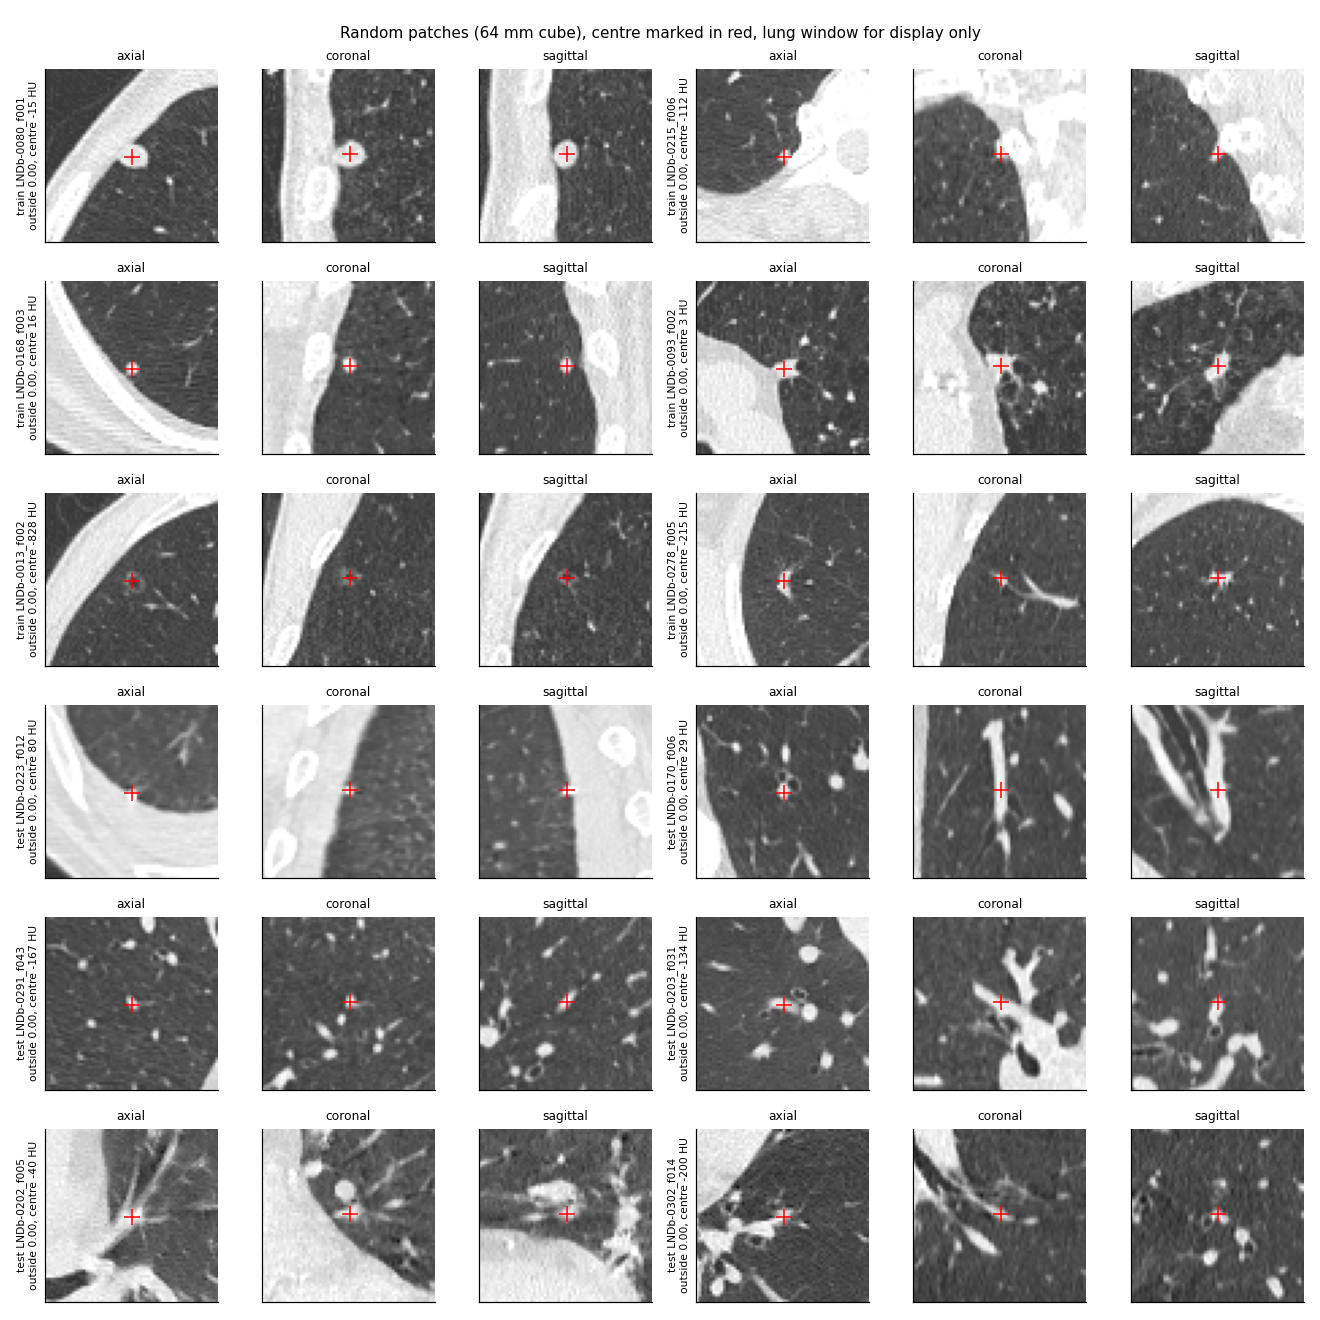

In [38]:
make_patch_qc_figure()
plt.close("all")            # the figure is shown from the saved file below
from IPython.display import Image
Image(filename=str(QC_FIGURE_FILE))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the patches already tell us
  </h3>
    <p>
    The tissue at the centre is denser in the test rows than in the training nodules. This fits the idea that the test file contains many structures that are not nodules (vessels, scars)-
  </p>
</div>

In [ ]:
table = pd.read_csv("nodule_table.csv")      # written by 03_tabela_nodulos.ipynb
lndb = table[table.dataset == "LNDb"]

In [39]:
def centre_hu(files):
    return np.array([np.load(PATCHES_DIR / f, mmap_mode="r")[31:34, 31:34, 31:34].mean() for f in files])

rated = lndb[lndb.mal_mean.notna()].nodule_uid.str.replace(r"_(\d+)$", lambda m: f"_f{int(m.group(1)):03d}", regex=True)
groups = {"train, rated nodules": train[train.patch_id.isin(rated)].file,
          "train, other findings": train[~train.patch_id.isin(rated)].file,
          "test": test[test.status == "ok"].file}
summary = {}
for name, files in groups.items():
    hu = centre_hu(files)
    summary[name] = {"n": len(hu), "median HU at centre": np.median(hu), "share above -300 HU": (hu > -300).mean()}
pd.DataFrame(summary).T.round(2)

,n,median HU at centre,share above -300 HU
"train, rated nodules",765.0,-242.96,0.57
"train, other findings",454.0,-185.52,0.67
test,2895.0,-103.30,0.81


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The same patches for LIDC-IDRI
  </h3>
</div>

In [40]:
lidc = pd.read_csv(PATCHES_DIR / "manifest_lidc.csv")
check = lidc.coord_check_mm
print(f"{len(lidc)} LIDC nodules, status: {lidc.status.value_counts().to_dict()}")
print(f"distance between the two computations: median {check.median():.3f} mm, 99th percentile {check.quantile(.99):.3f} mm")
print(f"position verified: {lidc.position_verified.sum()} | not verified: {(~lidc.position_verified).sum()} "
      f"(tilted series without a header point: {check.isna().sum()}, disagreement above 1 mm: {(check > 1).sum()})")

2663 LIDC nodules, status: {'ok': 2663}
distance between the two computations: median 0.000 mm, 99th percentile 0.000 mm
position verified: 2621 | not verified: 42 (tilted series without a header point: 36, disagreement above 1 mm: 6)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
    <p>
    Before using a LIDC patch we make sure it is centred on the right nodule. The centre is computed in two independent ways: Firstly it derives it from the DICOM header of the first slice, and the patch script lets SimpleITK convert the nodule's voxel position into millimetres using the geometry of the scan. If both give the same point, the patch is in the right place. For 2619 nodules the two points agree to less than a micrometre, and for two more within 0.52 mm, less than half a voxel. Six nodules in five series disagree by more than 1 mm, because pylidc and SimpleITK order the slices differently in those series, so the same slice number points to different slices. Another 36 nodules are in tilted series, where the header method does not apply, so their position cannot be confirmed. We leave these 42 nodules (1.6%) out: losing a few examples costs little, while a patch centred on the wrong tissue would teach the size model a wrong measurement. As a visual check, the figure below shows six random verified patches with a red cross at the centre, which should sit on the nodule. 
    </p>
</div>

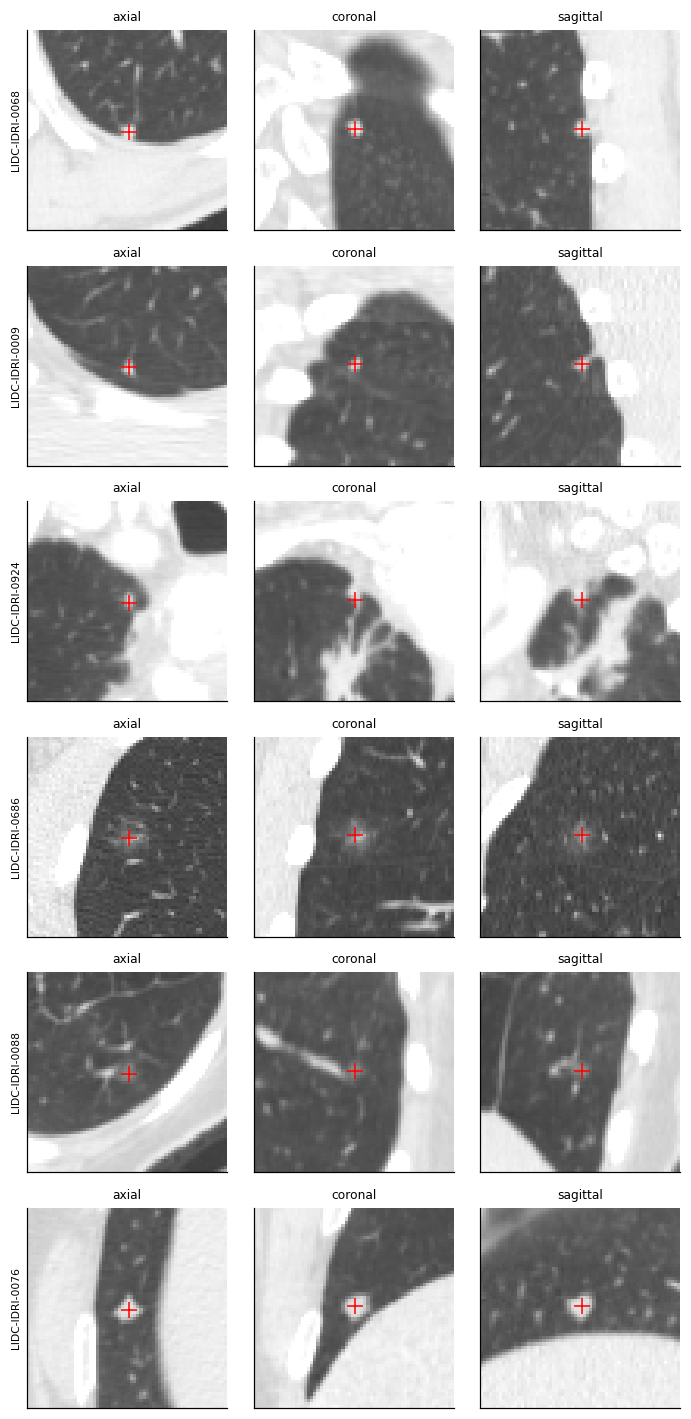

LIDC verified nodules: median HU at the centre -177, share above -300 HU 0.63


In [41]:
rng = np.random.default_rng(0)
picks = lidc[lidc.position_verified].iloc[rng.choice(lidc.position_verified.sum(), 6, replace=False)]
fig, axes = plt.subplots(6, 3, figsize=(6.5, 13))
for row_axes, item in zip(axes, picks.itertuples()):
    patch = np.load(PATCHES_DIR / item.file)
    views = (patch[CENTRE_INDEX], patch[:, CENTRE_INDEX, :], patch[:, :, CENTRE_INDEX])
    for axis, view, name in zip(row_axes, views, ("axial", "coronal", "sagittal")):
        axis.imshow(view, cmap="gray", vmin=-1350, vmax=150, origin="lower" if name != "axial" else "upper")
        axis.plot(CENTRE_INDEX, CENTRE_INDEX, "r+", markersize=10)
        axis.set_xticks([]); axis.set_yticks([]); axis.set_title(name, fontsize=8)
    row_axes[0].set_ylabel(item.patch_id[:14], fontsize=7)
plt.tight_layout(); plt.show()

lidc_hu = centre_hu(lidc[lidc.position_verified].file)
print(f"LIDC verified nodules: median HU at the centre {np.median(lidc_hu):.0f}, share above -300 HU {(lidc_hu > -300).mean():.2f}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The cube is 64 mm, so a nodule bigger than about 40 mm would be cut. In LNDb nodules this large are rare, and the next notebook counts them.</li>
    <li style="margin-bottom: 8px;">25 training and 47 test patches have more than 5% of their voxels outside the scan (near the edge of the volume). They are kept and flagged.</li>
    <li style="margin-bottom: 8px;">42 LIDC nodules (1.6%) whose position could not be confirmed are not used.</li>
  </ul>
</div>